In [1]:

%pip install pandas numpy matplotlib seaborn scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

df = pd.read_csv("data/train.csv")

# Display first five rows
df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:

print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Dataset Shape: (1460, 81)
Total Rows: 1460
Total Columns: 81


In [5]:

# Display column names
print(df.columns.tolist())

# Check column data types and non-null counts
df.info()


['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

In [6]:

print("Target Variable: SalePrice")

print("First 5 house prices:")
print(df["SalePrice"].head())

print("Missing target values:",
      df["SalePrice"].isnull().sum())


Target Variable: SalePrice
First 5 house prices:
0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64
Missing target values: 0


Stage 2 — Data Understanding & Exploratory Data Analysis (EDA)

In [7]:

# Display summary statistics
df.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [8]:

# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = df.select_dtypes(
    include=["object"]
).columns

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))


Numerical columns: 38
Categorical columns: 43


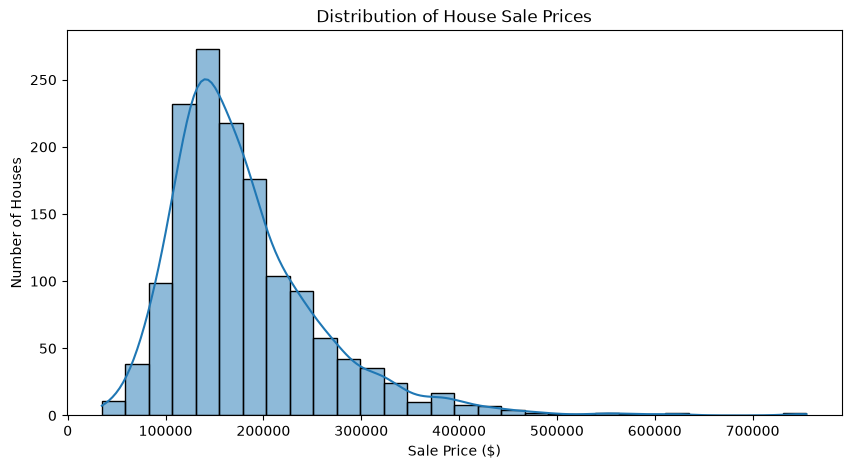

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["SalePrice"],
    bins=30,
    kde=True,
    
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")

plt.show()

In [11]:

print("SalePrice Skewness:",
      df["SalePrice"].skew())


SalePrice Skewness: 1.8828757597682129


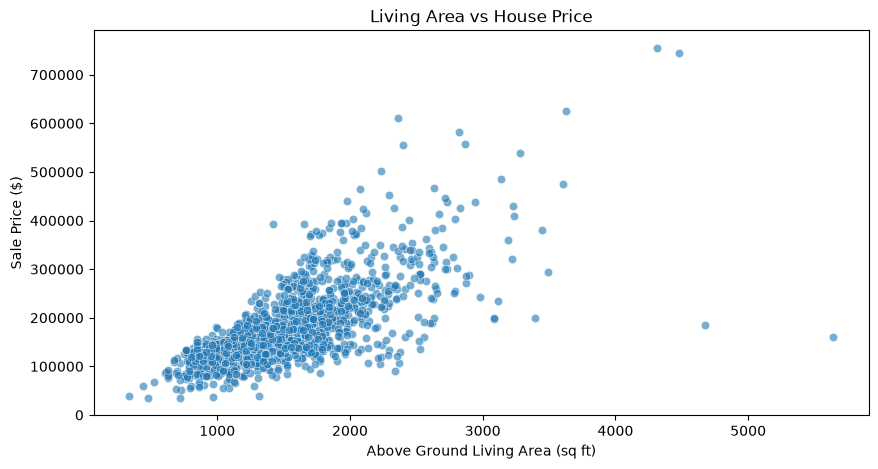

In [12]:

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.6
)

plt.title("Living Area vs House Price")
plt.xlabel("Above Ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")

plt.show()


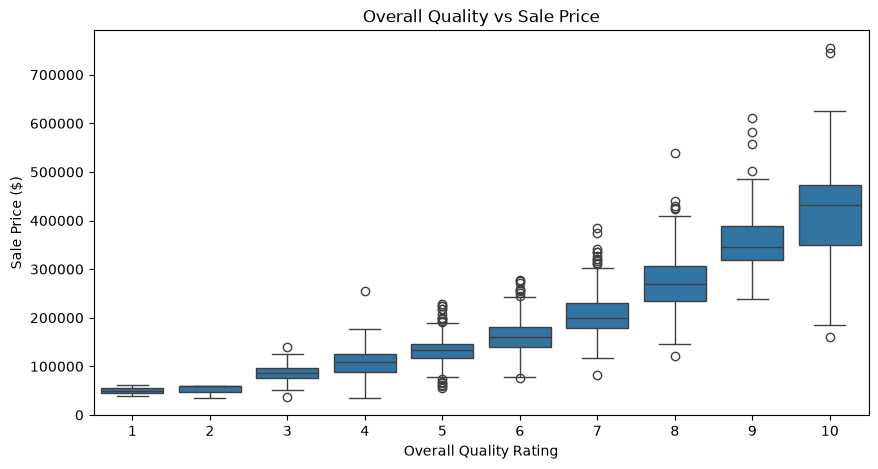

In [13]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="OverallQual",
    y="SalePrice"
)

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality Rating")
plt.ylabel("Sale Price ($)")

plt.show()


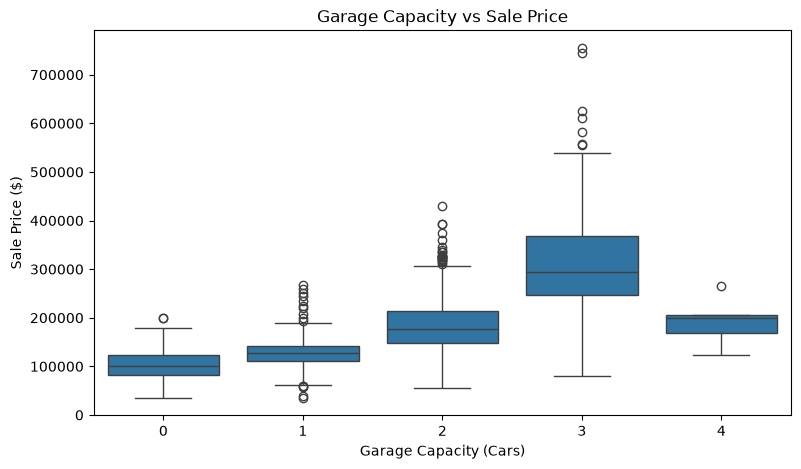

In [14]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="GarageCars",
    y="SalePrice"
)

plt.title("Garage Capacity vs Sale Price")
plt.xlabel("Garage Capacity (Cars)")
plt.ylabel("Sale Price ($)")

plt.show()


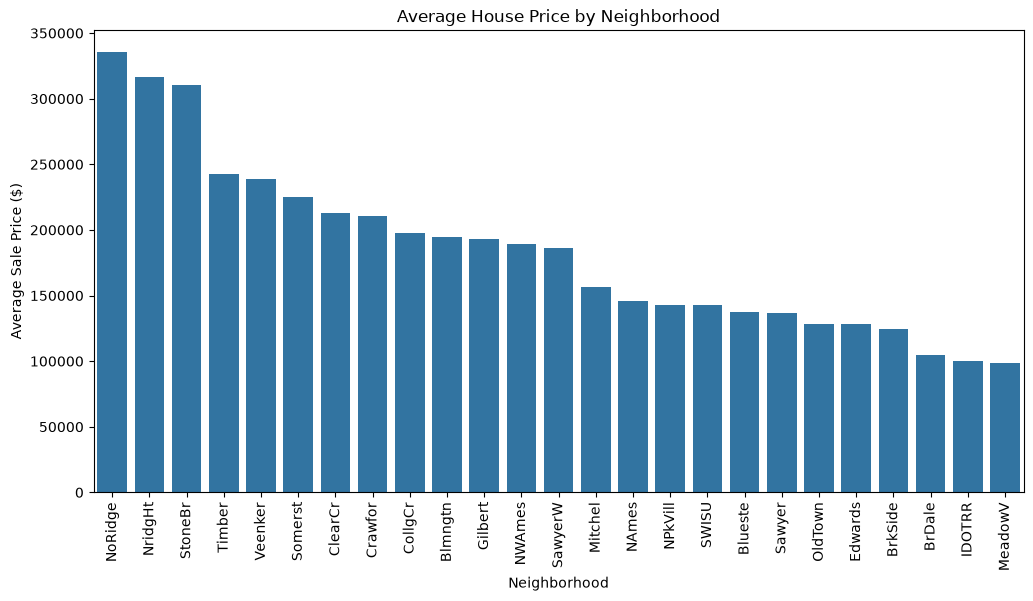

In [15]:

neighborhood_price = (
    df.groupby("Neighborhood")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=neighborhood_price.index,
    y=neighborhood_price.values
)

plt.xticks(rotation=90)
plt.title("Average House Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Average Sale Price ($)")

plt.show()


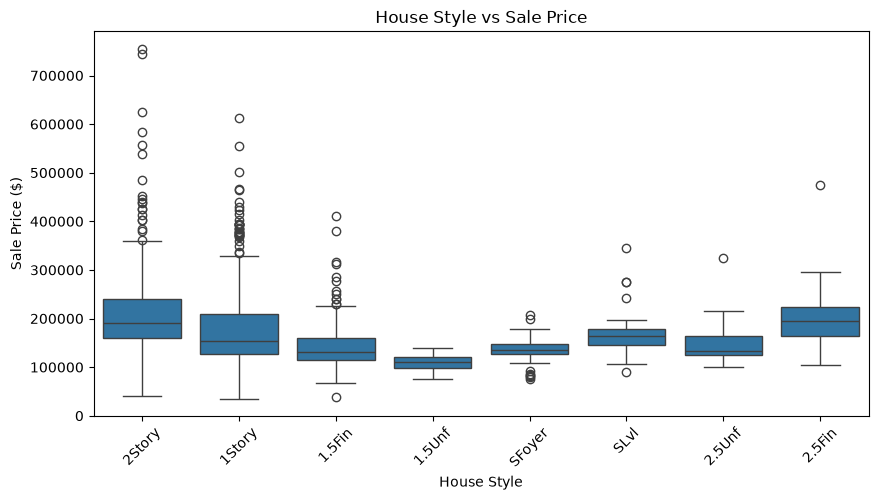

In [16]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="HouseStyle",
    y="SalePrice"
)

plt.title("House Style vs Sale Price")
plt.xlabel("House Style")
plt.ylabel("Sale Price ($)")

plt.xticks(rotation=45)
plt.show()


In [17]:

# Select only numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlations with SalePrice
correlation = (
    numeric_df.corr()["SalePrice"]
    .sort_values(ascending=False)
)

print(correlation.head(11))


SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


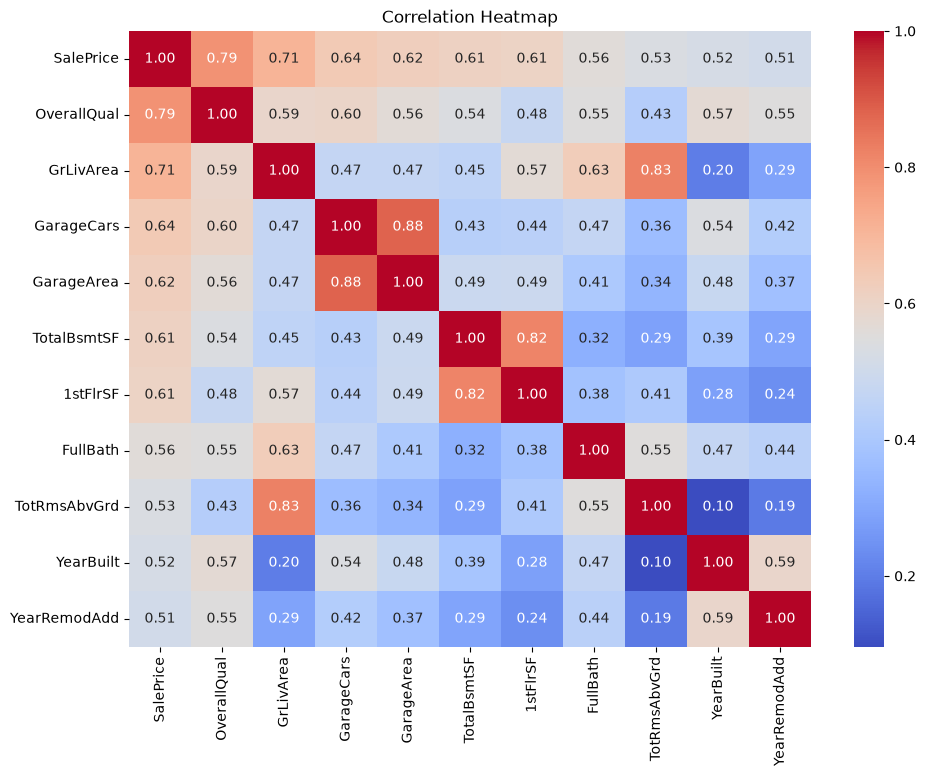

In [18]:

# Select top 10 features, including SalePrice
top_features = correlation.head(11).index

plt.figure(figsize=(11, 8))

sns.heatmap(
    numeric_df[top_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


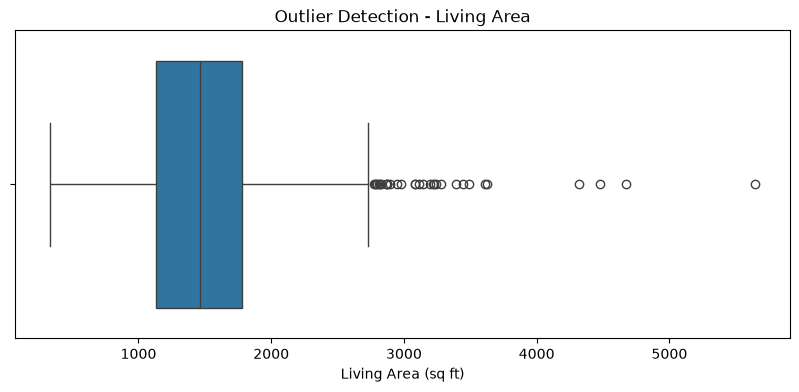

In [19]:

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["GrLivArea"]
)

plt.title("Outlier Detection - Living Area")
plt.xlabel("Living Area (sq ft)")

plt.show()


In [20]:

# Inspect unusually large houses
large_houses = df[
    df["GrLivArea"] > 4000
][["GrLivArea", "SalePrice", "OverallQual"]]

print(large_houses)


      GrLivArea  SalePrice  OverallQual
523        4676     184750           10
691        4316     755000           10
1182       4476     745000           10
1298       5642     160000           10


In [21]:

# Count missing values in each column
missing_values = (
    df.isnull().sum()
    .sort_values(ascending=False)
)

# Show columns with missing values
print(missing_values[missing_values > 0])


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [22]:

missing_percent = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_percent[missing_percent > 0])


PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageYrBlt      5.547945
GarageCond       5.547945
GarageType       5.547945
GarageFinish     5.547945
GarageQual       5.547945
BsmtFinType2     2.602740
BsmtExposure     2.602740
BsmtQual         2.534247
BsmtCond         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64


Stage 3 — Missing Value Analysis & Imputation

In [23]:

# Create a working copy
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)


Original shape: (1460, 81)
Working copy shape: (1460, 81)


In [24]:

# Categorical features where NA indicates absence
none_cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

# Replace missing values with "None"
for col in none_cols:
    df_clean[col] = df_clean[col].fillna("None")

print(
    df_clean[none_cols].isnull().sum()
)


PoolQC          0
MiscFeature     0
Alley           0
Fence           0
FireplaceQu     0
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
dtype: int64


In [25]:

# Check median before imputation
print(
    "LotFrontage Median:",
    df_clean["LotFrontage"].median()
)

# Fill missing values with median
df_clean["LotFrontage"] = (
    df_clean["LotFrontage"].fillna(
        df_clean["LotFrontage"].median()
    )
)

print(
    "Missing LotFrontage:",
    df_clean["LotFrontage"].isnull().sum()
)


LotFrontage Median: 69.0
Missing LotFrontage: 0


In [26]:

# Fill missing garage construction years
df_clean["GarageYrBlt"] = (
    df_clean["GarageYrBlt"].fillna(0)
)

print(
    "Missing GarageYrBlt:",
    df_clean["GarageYrBlt"].isnull().sum()
)


Missing GarageYrBlt: 0


In [27]:

df_clean["MasVnrArea"] = (
    df_clean["MasVnrArea"].fillna(
        df_clean["MasVnrArea"].median()
    )
)

print(
    "Missing MasVnrArea:",
    df_clean["MasVnrArea"].isnull().sum()
)


Missing MasVnrArea: 0


In [28]:

# Electrical: Fill with most frequent category
df_clean["Electrical"] = (
    df_clean["Electrical"].fillna(
        df_clean["Electrical"].mode()[0]
    )
)

# MasVnrType: Preserve unknown values
df_clean["MasVnrType"] = (
    df_clean["MasVnrType"].fillna("Missing")
)

print(
    df_clean[
        ["Electrical", "MasVnrType"]
    ].isnull().sum()
)


Electrical    0
MasVnrType    0
dtype: int64


In [29]:

# Check remaining missing values
remaining_missing = (
    df_clean.isnull().sum()
)

print(
    "Total Missing Values:",
    remaining_missing.sum()
)

print(
    "Columns with Missing Values:",
    (remaining_missing > 0).sum()
)

print(
    "Dataset Shape:",
    df_clean.shape
)


Total Missing Values: 0
Columns with Missing Values: 0
Dataset Shape: (1460, 81)


In [30]:

print(
    "Missing Values Before:",
    df.isnull().sum().sum()
)

print(
    "Missing Values After:",
    df_clean.isnull().sum().sum()
)


Missing Values Before: 7829
Missing Values After: 0


In [31]:

from sklearn.impute import SimpleImputer

# Demonstration only: use the original data
X_demo = df[["LotFrontage"]]

# Split before fitting the imputer
X_train_demo, X_test_demo = train_test_split(
    X_demo,
    test_size=0.2,
    random_state=42
)

# Create a median imputer
imputer = SimpleImputer(strategy="median")

# Learn median from training data only
X_train_imputed = imputer.fit_transform(
    X_train_demo
)

# Apply the same median to test data
X_test_imputed = imputer.transform(
    X_test_demo
)

print("Training missing values:",
      np.isnan(X_train_imputed).sum())

print("Testing missing values:",
      np.isnan(X_test_imputed).sum())


Training missing values: 0
Testing missing values: 0


Stage 4 — Categorical Encoding

In [32]:

# Select categorical columns
categorical_cols = df_clean.select_dtypes(
    include=["object"]
).columns

print("Total categorical columns:", len(categorical_cols))

print(categorical_cols.tolist())


Total categorical columns: 43
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [33]:

# Check unique categories
print("Neighborhood:")
print(df_clean["Neighborhood"].unique())

print("\nExterior Quality:")
print(df_clean["ExterQual"].unique())

print("\nHouse Style:")
print(df_clean["HouseStyle"].unique())


Neighborhood:
['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer' 'NridgHt' 'NAmes' 'SawyerW' 'IDOTRR'
 'MeadowV' 'Edwards' 'Timber' 'Gilbert' 'StoneBr' 'ClearCr' 'NPkVill'
 'Blmngtn' 'BrDale' 'SWISU' 'Blueste']

Exterior Quality:
['Gd' 'TA' 'Ex' 'Fa']

House Style:
['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']


In [34]:

# Check unique categories
print("Neighborhood:")
print(df_clean["Neighborhood"].unique())

print("\nExterior Quality:")
print(df_clean["ExterQual"].unique())

print("\nHouse Style:")
print(df_clean["HouseStyle"].unique())


Neighborhood:
['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer' 'NridgHt' 'NAmes' 'SawyerW' 'IDOTRR'
 'MeadowV' 'Edwards' 'Timber' 'Gilbert' 'StoneBr' 'ClearCr' 'NPkVill'
 'Blmngtn' 'BrDale' 'SWISU' 'Blueste']

Exterior Quality:
['Gd' 'TA' 'Ex' 'Fa']

House Style:
['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']


In [35]:

# Define quality ranking
quality_mapping = {
    "None": 0,
    "Po": 1,
    "Fa": 2,
    "TA": 3,
    "Gd": 4,
    "Ex": 5
}

# Create a separate working copy
df_ordinal = df_clean.copy()

# Encode exterior quality
df_ordinal["ExterQual"] = (
    df_ordinal["ExterQual"].map(quality_mapping)
)

print(df_ordinal["ExterQual"].head())


0    4
1    3
2    4
3    3
4    4
Name: ExterQual, dtype: int64


In [36]:

# Create a demonstration copy
df_onehot = df_clean[["Neighborhood"]].copy()

# Apply One-Hot Encoding
df_onehot = pd.get_dummies(
    df_onehot,
    columns=["Neighborhood"],
    dtype=int
)

print(df_onehot.head())

print("Shape:", df_onehot.shape)


   Neighborhood_Blmngtn  Neighborhood_Blueste  Neighborhood_BrDale  \
0                     0                     0                    0   
1                     0                     0                    0   
2                     0                     0                    0   
3                     0                     0                    0   
4                     0                     0                    0   

   Neighborhood_BrkSide  Neighborhood_ClearCr  Neighborhood_CollgCr  \
0                     0                     0                     1   
1                     0                     0                     0   
2                     0                     0                     1   
3                     0                     0                     0   
4                     0                     0                     0   

   Neighborhood_Crawfor  Neighborhood_Edwards  Neighborhood_Gilbert  \
0                     0                     0                     0   
1         

In [37]:

# Copy the ordinal-encoded dataset
df_encoded = df_ordinal.copy()

# Find remaining categorical columns
remaining_categorical = df_encoded.select_dtypes(
    include=["object"]
).columns

print(
    "Remaining categorical columns:",
    len(remaining_categorical)
)

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(
    df_encoded,
    columns=remaining_categorical.tolist(),
    dtype=int
)

print("Encoded dataset shape:", df_encoded.shape)


Remaining categorical columns: 42
Encoded dataset shape: (1460, 301)


In [38]:

# Check remaining categorical columns
print(
    "Categorical columns remaining:",
    len(
        df_encoded.select_dtypes(
            include=["object"]
        ).columns
    )
)

# Check missing values
print(
    "Missing values:",
    df_encoded.isnull().sum().sum()
)

# Check shape
print(
    "Final shape:",
    df_encoded.shape
)


Categorical columns remaining: 0
Missing values: 0
Final shape: (1460, 301)


In [39]:

from sklearn.preprocessing import OneHotEncoder

# Use original categorical data for demonstration
X_demo = df[["Neighborhood"]]

# Split into training and testing
X_train_demo, X_test_demo = train_test_split(
    X_demo,
    test_size=0.2,
    random_state=42
)

# Create encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Fit only on training data
X_train_encoded = encoder.fit_transform(
    X_train_demo
)

# Transform testing data
X_test_encoded = encoder.transform(
    X_test_demo
)

print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)


Training shape: (1168, 25)
Testing shape: (292, 25)


Stage 5 — Feature Engineering

In [40]:

# Create a fresh copy of the original dataset
df_fe = df.copy()

print("Dataset shape:", df_fe.shape)
print(df_fe.head())


Dataset shape: (1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePri

In [41]:

# Create total floor area
df_fe["TotalSF"] = (
    df_fe["TotalBsmtSF"]
    + df_fe["1stFlrSF"]
    + df_fe["2ndFlrSF"]
)

# Inspect the new feature
print(
    df_fe[
        [
            "TotalBsmtSF",
            "1stFlrSF",
            "2ndFlrSF",
            "TotalSF"
        ]
    ].head()
)


   TotalBsmtSF  1stFlrSF  2ndFlrSF  TotalSF
0          856       856       854     2566
1         1262      1262         0     2524
2          920       920       866     2706
3          756       961       756     2473
4         1145      1145      1053     3343


In [42]:

# Age of house at the time of sale
df_fe["HouseAge"] = (
    df_fe["YrSold"] - df_fe["YearBuilt"]
)

# Years since the last remodeling
df_fe["RemodelAge"] = (
    df_fe["YrSold"] - df_fe["YearRemodAdd"]
)

print(
    df_fe[
        [
            "YearBuilt",
            "YearRemodAdd",
            "YrSold",
            "HouseAge",
            "RemodelAge"
        ]
    ].head()
)


   YearBuilt  YearRemodAdd  YrSold  HouseAge  RemodelAge
0       2003          2003    2008         5           5
1       1976          1976    2007        31          31
2       2001          2002    2008         7           6
3       1915          1970    2006        91          36
4       2000          2000    2008         8           8


In [43]:

df_fe["TotalBathrooms"] = (
    df_fe["FullBath"]
    + 0.5 * df_fe["HalfBath"]
    + df_fe["BsmtFullBath"]
    + 0.5 * df_fe["BsmtHalfBath"]
)

print(
    df_fe[
        [
            "FullBath",
            "HalfBath",
            "BsmtFullBath",
            "BsmtHalfBath",
            "TotalBathrooms"
        ]
    ].head()
)


   FullBath  HalfBath  BsmtFullBath  BsmtHalfBath  TotalBathrooms
0         2         1             1             0             3.5
1         2         0             0             1             2.5
2         2         1             1             0             3.5
3         1         0             1             0             2.0
4         2         1             1             0             3.5


In [44]:

# Create a binary garage indicator
df_fe["HasGarage"] = (
    df_fe["GarageArea"] > 0
).astype(int)

print(
    df_fe[
        ["GarageArea", "HasGarage"]
    ].head(10)
)


   GarageArea  HasGarage
0         548          1
1         460          1
2         608          1
3         642          1
4         836          1
5         480          1
6         636          1
7         484          1
8         468          1
9         205          1


In [45]:

porch_columns = [
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "WoodDeckSF"
]

df_fe["TotalPorchSF"] = (
    df_fe[porch_columns].sum(axis=1)
)

print(
    df_fe[
        porch_columns + ["TotalPorchSF"]
    ].head()
)


   OpenPorchSF  EnclosedPorch  3SsnPorch  ScreenPorch  WoodDeckSF  \
0           61              0          0            0           0   
1            0              0          0            0         298   
2           42              0          0            0           0   
3           35            272          0            0           0   
4           84              0          0            0         192   

   TotalPorchSF  
0            61  
1           298  
2            42  
3           307  
4           276  


In [46]:

new_features = [
    "TotalSF",
    "HouseAge",
    "RemodelAge",
    "TotalBathrooms",
    "HasGarage",
    "TotalPorchSF"
]

print(df_fe[new_features].head())

print("\nSummary statistics:")
print(df_fe[new_features].describe())



   TotalSF  HouseAge  RemodelAge  TotalBathrooms  HasGarage  TotalPorchSF
0     2566         5           5             3.5          1            61
1     2524        31          31             2.5          1           298
2     2706         7           6             3.5          1            42
3     2473        91          36             2.0          1           307
4     3343         8           8             3.5          1           276

Summary statistics:
            TotalSF     HouseAge   RemodelAge  TotalBathrooms    HasGarage  \
count   1460.000000  1460.000000  1460.000000     1460.000000  1460.000000   
mean    2567.048630    36.547945    22.950000        2.210616     0.944521   
std      821.714421    30.250152    20.640653        0.785399     0.228992   
min      334.000000     0.000000    -1.000000        1.000000     0.000000   
25%     2009.500000     8.000000     4.000000        2.000000     1.000000   
50%     2474.000000    35.000000    14.000000        2.000000     1

In [47]:

age_columns = [
    "HouseAge",
    "RemodelAge"
]

for col in age_columns:
    print(
        col,
        "Negative values:",
        (df_fe[col] < 0).sum()
    )


HouseAge Negative values: 0
RemodelAge Negative values: 1


In [48]:
# Find the house with a negative RemodelAge
df_fe.loc[
    df_fe["RemodelAge"] < 0,
    ["Id", "YearBuilt", "YearRemodAdd", "YrSold", "RemodelAge", "SalePrice"]
]

,Id,YearBuilt,YearRemodAdd,YrSold,RemodelAge,SalePrice
523,524,2007,2008,2007,-1,184750


In [49]:
df_fe.loc[
    df_fe["RemodelAge"] < 0,
    ["Id", "YearBuilt", "YearRemodAdd", "YrSold", "RemodelAge"]
]

,Id,YearBuilt,YearRemodAdd,YrSold,RemodelAge
523,524,2007,2008,2007,-1


In [50]:
df_fe["RemodelAge"] = (
    df_fe["YrSold"] - df_fe["YearRemodAdd"]
)

In [51]:
print(
    "Negative RemodelAge values:",
    (df_fe["RemodelAge"] < 0).sum()
)

Negative RemodelAge values: 1


In [52]:
negative_rows = df_fe.loc[
    df_fe["RemodelAge"] < 0,
    ["Id", "YearBuilt", "YearRemodAdd", "YrSold", "RemodelAge"]
]

print(negative_rows)

      Id  YearBuilt  YearRemodAdd  YrSold  RemodelAge
523  524       2007          2008    2007          -1


In [53]:
print(
    df_fe.loc[negative_rows.index, "YrSold"]
    - df_fe.loc[negative_rows.index, "YearRemodAdd"]
)

523   -1
dtype: int64


In [54]:
df.loc[
    df["Id"] == 524,
    ["Id", "YearBuilt", "YearRemodAdd", "YrSold", "SalePrice"]
]

,Id,YearBuilt,YearRemodAdd,YrSold,SalePrice
523,524,2007,2008,2007,184750


In [55]:
df_fe.loc[
    df_fe["Id"] == 524,
    "RemodelAge"
] = 0

In [56]:
print(
    "Negative RemodelAge values:",
    (df_fe["RemodelAge"] < 0).sum()
)

Negative RemodelAge values: 0


In [57]:

age_columns = [
    "HouseAge",
    "RemodelAge"
]

for col in age_columns:
    print(
        col,
        "Negative values:",
        (df_fe[col] < 0).sum()
    )


HouseAge Negative values: 0
RemodelAge Negative values: 0


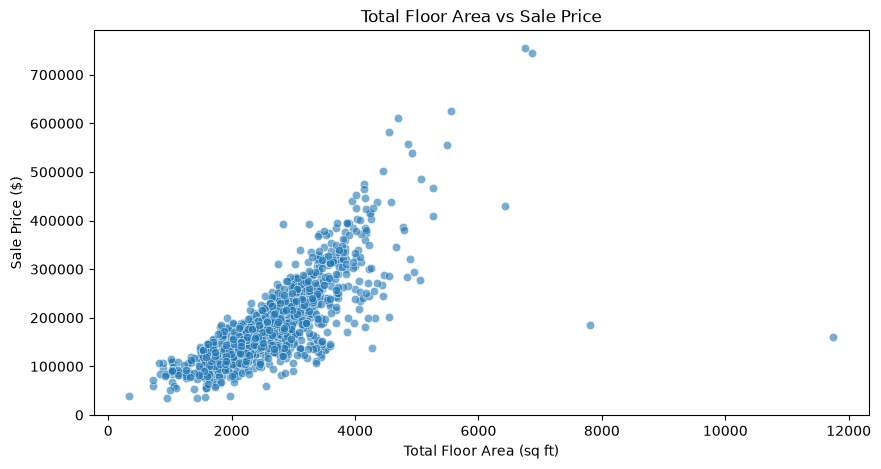

In [58]:

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_fe,
    x="TotalSF",
    y="SalePrice",
    alpha=0.6
)

plt.title("Total Floor Area vs Sale Price")
plt.xlabel("Total Floor Area (sq ft)")
plt.ylabel("Sale Price ($)")

plt.show()


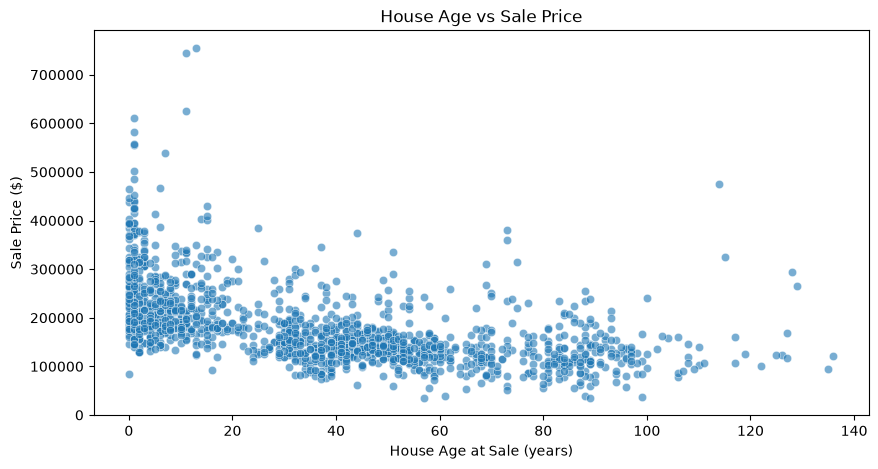

In [59]:

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_fe,
    x="HouseAge",
    y="SalePrice",
    alpha=0.6
)

plt.title("House Age vs Sale Price")
plt.xlabel("House Age at Sale (years)")
plt.ylabel("Sale Price ($)")

plt.show()


In [60]:

feature_correlations = (
    df_fe[new_features + ["SalePrice"]]
    .corr()["SalePrice"]
    .sort_values(ascending=False)
)

print(feature_correlations)


SalePrice         1.000000
TotalSF           0.782260
TotalBathrooms    0.631731
TotalPorchSF      0.390993
HasGarage         0.236832
RemodelAge       -0.509096
HouseAge         -0.523350
Name: SalePrice, dtype: float64


Stage 6 — Train/Test Split & Preprocessing Pipeline

In [61]:
# Input features: everything except the target and identifier
X = df_fe.drop(columns=["SalePrice", "Id"])

# Target: the house price we want to predict
y = df_fe["SalePrice"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target preview:")
print(y.head())

Features shape: (1460, 85)
Target shape: (1460,)
Target preview:
0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64


In [62]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1168, 85)
X_test shape: (292, 85)
y_train shape: (1168,)
y_test shape: (292,)


In [63]:
# Identify column types using the training data
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nCategorical feature examples:")
print(categorical_features[:10])

Number of numerical features: 42
Number of categorical features: 43

Categorical feature examples:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1']


In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [65]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

In [66]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

In [67]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [68]:
# Learn imputation values and category mappings from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same learned transformations to testing data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (1168, 307)
Processed testing shape: (292, 307)


In [69]:
# Check dimensions
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

# Check for missing values after preprocessing
import numpy as np
from scipy import sparse

if sparse.issparse(X_train_processed):
    train_missing = np.isnan(X_train_processed.data).sum()
else:
    train_missing = np.isnan(X_train_processed).sum()

if sparse.issparse(X_test_processed):
    test_missing = np.isnan(X_test_processed.data).sum()
else:
    test_missing = np.isnan(X_test_processed).sum()

print("Missing values in training data:", train_missing)
print("Missing values in testing data:", test_missing)

# Verify feature counts match
print(
    "Feature counts match:",
    X_train_processed.shape[1] == X_test_processed.shape[1]
)

Training shape: (1168, 307)
Testing shape: (292, 307)
Missing values in training data: 0
Missing values in testing data: 0
Feature counts match: True


Stage 7 — Train a Linear Regression Model

In [70]:
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train using the training data
lr_model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [71]:
# Predict house prices for the test split
y_pred = lr_model.predict(X_test_processed)

print("Number of predictions:", len(y_pred))
print("\nFirst 10 predicted prices:")
print(y_pred[:10])

Number of predictions: 292

First 10 predicted prices:
[160591.44069533 342494.79801398  92158.00735822 181121.51366185
 323163.09857875  64889.55345104 244599.33538417 140981.32747066
  56742.97693199 145741.90777873]


In [72]:
import pandas as pd

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison["Difference"] = (
    comparison["Predicted Price"] - comparison["Actual Price"]
)

print(comparison.head(10).round(2))

   Actual Price  Predicted Price  Difference
0        154500        160591.44     6091.44
1        325000        342494.80    17494.80
2        115000         92158.01   -22841.99
3        159000        181121.51    22121.51
4        315500        323163.10     7663.10
5         75500         64889.55   -10610.45
6        311500        244599.34   -66900.66
7        146000        140981.33    -5018.67
8         84500         56742.98   -27757.02
9        135500        145741.91    10241.91


In [73]:
print("Intercept:", lr_model.intercept_)
print("Number of learned coefficients:", len(lr_model.coef_))

Intercept: 333584.82671083126
Number of learned coefficients: 307


Stage 8 — Model Evaluation (MAE, RMSE, and R²)

In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("Linear Regression Model Evaluation")
print("----------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Linear Regression Model Evaluation
----------------------------------
MAE  : 20258.98
MSE  : 952289313.40
RMSE : 30859.19
R²   : 0.8758


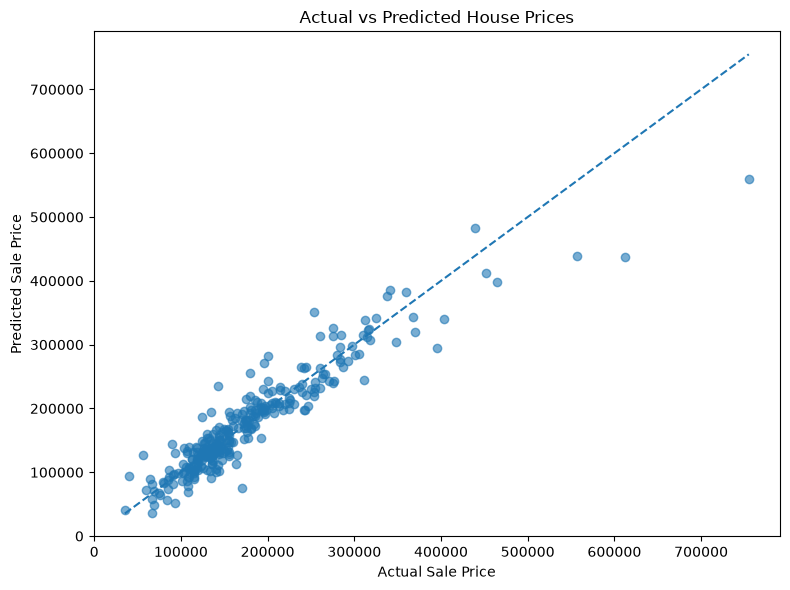

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Ideal prediction line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()

In [76]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing: impute, then scale
ridge_numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing: impute, then one-hot encode
ridge_categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

# Combine both preprocessing pipelines
ridge_preprocessor = ColumnTransformer(
    transformers=[
        ("num", ridge_numeric_transformer, numeric_features),
        ("cat", ridge_categorical_transformer, categorical_features)
    ]
)

# Fit preprocessing on training data only
X_train_ridge = ridge_preprocessor.fit_transform(X_train)

# Transform the test data using the same fitted preprocessing
X_test_ridge = ridge_preprocessor.transform(X_test)

print("Ridge training shape:", X_train_ridge.shape)
print("Ridge testing shape:", X_test_ridge.shape)

Ridge training shape: (1168, 307)
Ridge testing shape: (292, 307)


In [77]:
ridge_model = Ridge(alpha=10)

ridge_model.fit(X_train_ridge, y_train)

ridge_pred = ridge_model.predict(X_test_ridge)

print("Ridge Regression trained successfully!")
print("Number of predictions:", len(ridge_pred))

Ridge Regression trained successfully!
Number of predictions: 292


In [78]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_pred)
)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression Evaluation")
print("----------------------------")
print(f"MAE  : {ridge_mae:.2f}")
print(f"RMSE : {ridge_rmse:.2f}")
print(f"R²   : {ridge_r2:.4f}")

Ridge Regression Evaluation
----------------------------
MAE  : 19164.34
RMSE : 30515.27
R²   : 0.8786


In [79]:
comparison_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Linear Regression": [mae, rmse, r2],
    "Ridge Regression": [
        ridge_mae,
        ridge_rmse,
        ridge_r2
    ]
})

print(comparison_df.round(4))

  Metric  Linear Regression  Ridge Regression
0    MAE         20258.9829        19164.3430
1   RMSE         30859.1852        30515.2744
2     R²             0.8758            0.8786


In [80]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

# Keep preprocessing inside the pipeline
ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", ridge_preprocessor),
        ("model", Ridge())
    ]
)

# Candidate regularization strengths
param_grid = {
    "model__alpha": [0.1, 1, 10, 100, 1000]
}

grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

# Tune using training data only
grid_search.fit(X_train, y_train)

print("Best alpha:", grid_search.best_params_["model__alpha"])
print(
    "Best cross-validation MAE:",
    round(-grid_search.best_score_, 2)
)

Best alpha: 10
Best cross-validation MAE: 18072.4


In [81]:
best_ridge_model = grid_search.best_estimator_

tuned_pred = best_ridge_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print("Tuned Ridge Regression")
print("-----------------------")
print(f"MAE  : {tuned_mae:.2f}")
print(f"RMSE : {tuned_rmse:.2f}")
print(f"R²   : {tuned_r2:.4f}")

Tuned Ridge Regression
-----------------------
MAE  : 19164.34
RMSE : 30515.27
R²   : 0.8786


Stage 10 — Final Predictions & Project Completion

In [82]:
final_results = pd.DataFrame({
    "ActualPrice": y_test.values,
    "PredictedPrice": tuned_pred
})

final_results["AbsoluteError"] = (
    final_results["ActualPrice"]
    - final_results["PredictedPrice"]
).abs()

print(final_results.head(10).round(2))

   ActualPrice  PredictedPrice  AbsoluteError
0       154500       160401.22        5901.22
1       325000       336566.33       11566.33
2       115000        97348.30       17651.70
3       159000       179054.69       20054.69
4       315500       337885.59       22385.59
5        75500        65650.13        9849.87
6       311500       247891.49       63608.51
7       146000       150162.06        4162.06
8        84500        64548.18       19951.82
9       135500       149887.26       14387.26


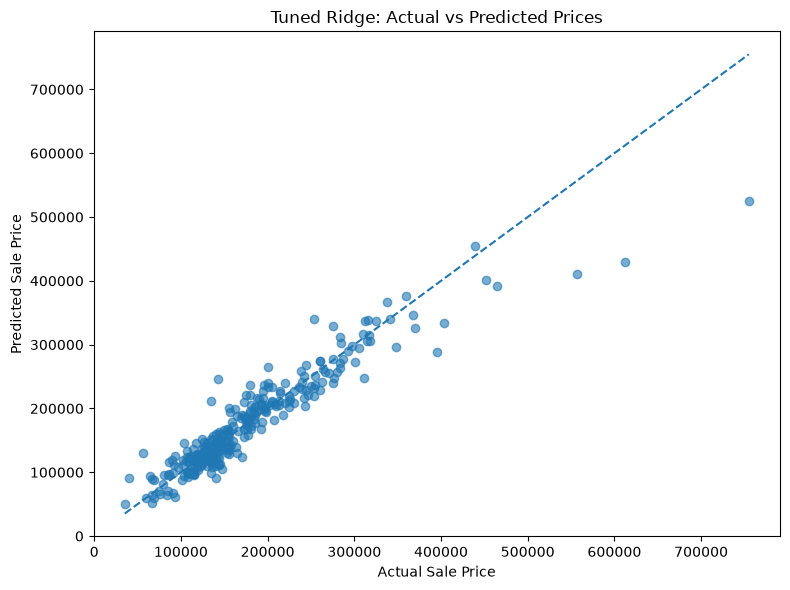

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, tuned_pred, alpha=0.6)

min_price = min(y_test.min(), tuned_pred.min())
max_price = max(y_test.max(), tuned_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Tuned Ridge: Actual vs Predicted Prices")
plt.tight_layout()
plt.show()

In [84]:
final_results.to_csv(
    "house_price_test_predictions.csv",
    index=False
)

print("Predictions saved successfully.")

Predictions saved successfully.
